# 03 – Evaluation: where does the market maker's PnL come from?

Run `python run_final.py` first. This notebook produces the final results and figures:

1. **PnL decomposition** per strategy: spread capture, adverse selection and inventory, in bp of value traded
2. **Markout curves** from 0 to 30 seconds, BTCUSDT vs DOGEUSDT, with the whole market's passive orders as a benchmark
3. **Break-even maker rebate** per strategy
4. **Equity curves** for the test day
5. **Final table** for the README

Figures are saved to `figures/`.

In [ ]:
import glob
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

INSTRUMENTS = {"BTCUSDT": {"data": "data/processed", "tick": 0.01},
               "DOGEUSDT": {"data": "data/processed_doge", "tick": 0.00001}}
RESULTS = "results/final"
TUNE_DAYS = ["2026-08-01", "2026-09-01"]
TEST_DAYS = ["2026-10-01"]
HORIZONS_S = [0, 0.1, 0.25, 0.5, 1, 2, 5, 10, 20, 30]
H_DECOMP_S = 10          # horizon that separates adverse selection from inventory PnL
DAY_MS = 86_400_000
NAMES = {"symmetric": "Baseline", "imbalance": "Imbalance filter", "as": "Avellaneda–Stoikov",
         "as_imbalance": "A–S + imbalance"}
os.makedirs("figures", exist_ok=True)

def nice(label):
    return NAMES.get(label.split("_theta")[0].split("_gamma")[0], label)

def period(day):
    return "test" if day in TEST_DAYS else "tune" if day in TUNE_DAYS else "other"

## Load book mids, real trades and backtest results

In [ ]:
def load_book(data):
    b = pd.read_parquet(f"{data}/book", columns=["event_ms", "bid_px_0", "ask_px_0"]).sort_values("event_ms", kind="stable")
    t = b.event_ms.to_numpy()
    day = t // DAY_MS
    day_end = pd.Series(t).groupby(day).transform("max").to_numpy()
    return {"t": t, "mid": ((b.bid_px_0 + b.ask_px_0) / 2).to_numpy(), "day": day, "day_end": day_end}

def mid_at(bk, times):
    """Mid price at each time (last book update at or before it), NaN if outside that day's data."""
    idx = np.searchsorted(bk["t"], times, side="right") - 1
    i = np.clip(idx, 0, None)
    ok = (idx >= 0) & (bk["day"][i] == times // DAY_MS) & (times <= bk["day_end"][i])
    return np.where(ok, bk["mid"][i], np.nan)

def load_runs(symbol, tick):
    runs = {}
    order = ["symmetric", "imbalance", "as_", "as_imbalance"]
    rank = lambda p: [i for i, o in enumerate(order) if os.path.basename(p.rstrip("/")).startswith(o)][-1]
    for d in sorted(glob.glob(f"{RESULTS}/{symbol}/*/"), key=rank):    # baseline first
        lab = os.path.basename(d.rstrip("/"))
        fills, eq = [], []
        for f in sorted(glob.glob(f"{d}fills_*.parquet")):
            day = os.path.basename(f)[6:16]
            x = pd.read_parquet(f).assign(day=day)
            x["price"] = x.price_ticks * tick
            x["mid0"] = x.mid_ticks * tick
            fills.append(x)
            e = pd.read_parquet(f"{d}equity_{day}.parquet")
            eq.append(e.assign(day=day))
        runs[lab] = {"fills": pd.concat(fills, ignore_index=True), "equity": pd.concat(eq, ignore_index=True)}
    return runs

books, runs, trades = {}, {}, {}
for sym, spec in INSTRUMENTS.items():
    books[sym] = load_book(spec["data"])
    runs[sym] = load_runs(sym, spec["tick"])
    trades[sym] = pd.read_parquet(f"{spec['data']}/trades", columns=["trade_ms", "price", "qty", "buyer_is_maker"])
    print(sym, "strategies:", [nice(k) for k in runs[sym]])

BTCUSDT strategies: ['Baseline', 'Imbalance filter', 'Avellaneda–Stoikov', 'A–S + imbalance']
DOGEUSDT strategies: ['Baseline', 'Imbalance filter', 'Avellaneda–Stoikov', 'A–S + imbalance']


## 1. PnL decomposition

For each fill (side = +1 buy, −1 sell; all in dollars, then divided by value traded):

- **spread capture** = side × (mid at fill − fill price): what you earn at the moment of the fill
- **adverse selection** = side × (mid after 10 s − mid at fill): how far the price moved against you
- **inventory** = total PnL − the two above: gains or losses from holding the position beyond 10 s

The three add up exactly to the backtest's gross PnL.

In [ ]:
rows = []
for sym in INSTRUMENTS:
    bk = books[sym]
    for lab, r in runs[sym].items():
        f, eq = r["fills"], r["equity"]
        mid_h = mid_at(bk, f.time.to_numpy() + H_DECOMP_S * 1000)
        f = f.assign(spread=f.side * (f.mid0 - f.price) * f.qty,
                     adverse=np.nan_to_num(f.side * (mid_h - f.mid0) * f.qty),
                     notional=f.qty * f.price)
        gross = eq.groupby("day").gross_pnl.last()
        for per in ("tune", "test"):
            days = [d for d in gross.index if period(d) == per]
            ff = f[f.day.isin(days)]
            if ff.empty:
                continue
            n, g = ff.notional.sum(), gross[days].sum()
            sp, ad = ff.spread.sum(), ff.adverse.sum()
            rows.append({"symbol": sym, "strategy": nice(lab), "period": per, "fills": len(ff),
                         "notional_$": n, "gross_pnl_$": g,
                         "gross_bps": 1e4 * g / n, "spread_bps": 1e4 * sp / n,
                         "adverse_bps": 1e4 * ad / n, "inventory_bps": 1e4 * (g - sp - ad) / n})
decomp = pd.DataFrame(rows)
decomp["breakeven_rebate_bps"] = -decomp.gross_bps
decomp.to_csv(f"{RESULTS}/decomposition_bps.csv", index=False)
decomp.round(3)

,symbol,strategy,period,fills,notional_$,gross_pnl_$,gross_bps,spread_bps,adverse_bps,inventory_bps,breakeven_rebate_bps
0,BTCUSDT,Baseline,tune,54749,2059606.382,-256.429,-1.245,-0.031,-1.038,-0.176,1.245
1,BTCUSDT,Baseline,test,45575,1835286.018,-228.213,-1.243,-0.035,-1.122,-0.086,1.243
2,BTCUSDT,Imbalance filter,tune,19509,941624.520,-116.305,-1.235,-0.021,-1.084,-0.130,1.235
3,BTCUSDT,Imbalance filter,test,13224,714829.245,-98.230,-1.374,-0.029,-1.151,-0.195,1.374
4,BTCUSDT,Avellaneda–Stoikov,tune,17311,933097.878,-119.433,-1.280,0.123,-1.236,-0.167,1.280
5,BTCUSDT,Avellaneda–Stoikov,test,11035,691945.261,-91.588,-1.324,0.161,-1.312,-0.173,1.324
6,BTCUSDT,A–S + imbalance,tune,8270,464964.094,-62.861,-1.352,0.150,-1.348,-0.154,1.352
7,BTCUSDT,A–S + imbalance,test,5147,351166.108,-45.500,-1.296,0.165,-1.394,-0.067,1.296
8,DOGEUSDT,Baseline,tune,64762,949923.362,-111.968,-1.179,-0.038,-1.224,0.083,1.179
9,DOGEUSDT,Baseline,test,60702,1345752.884,-158.639,-1.179,-0.131,-1.110,0.062,1.179


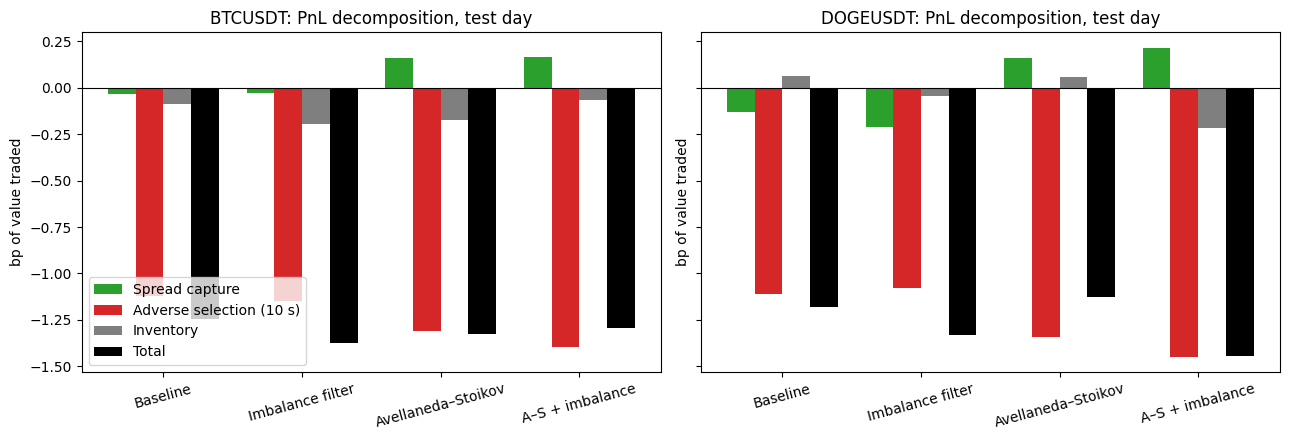

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
comps = [("spread_bps", "Spread capture", "tab:green"), ("adverse_bps", "Adverse selection (10 s)", "tab:red"),
         ("inventory_bps", "Inventory", "tab:grey"), ("gross_bps", "Total", "black")]
for ax, sym in zip(axes, INSTRUMENTS):
    d = decomp[(decomp.symbol == sym) & (decomp.period == "test")].reset_index(drop=True)
    x = np.arange(len(d)); w = 0.2
    for k, (col, name, colour) in enumerate(comps):
        ax.bar(x + (k - 1.5) * w, d[col], w, label=name, color=colour)
    ax.axhline(0, c="black", lw=0.8)
    ax.set_xticks(x); ax.set_xticklabels(d.strategy, rotation=15)
    ax.set_title(f"{sym}: PnL decomposition, test day"); ax.set_ylabel("bp of value traded")
axes[0].legend()
plt.tight_layout(); plt.savefig("figures/pnl_decomposition.png", dpi=150); plt.show()

## 2. Markout curves

Value-weighted markout of our fills at each horizon, and of **every real passive order in the market** (the passive side of every trade) as a benchmark.
The 0 s point of the market curve is inflated by the 100 ms book snapshots (the last mid can be stale during fast moves), so compare the **shape** of the curves.

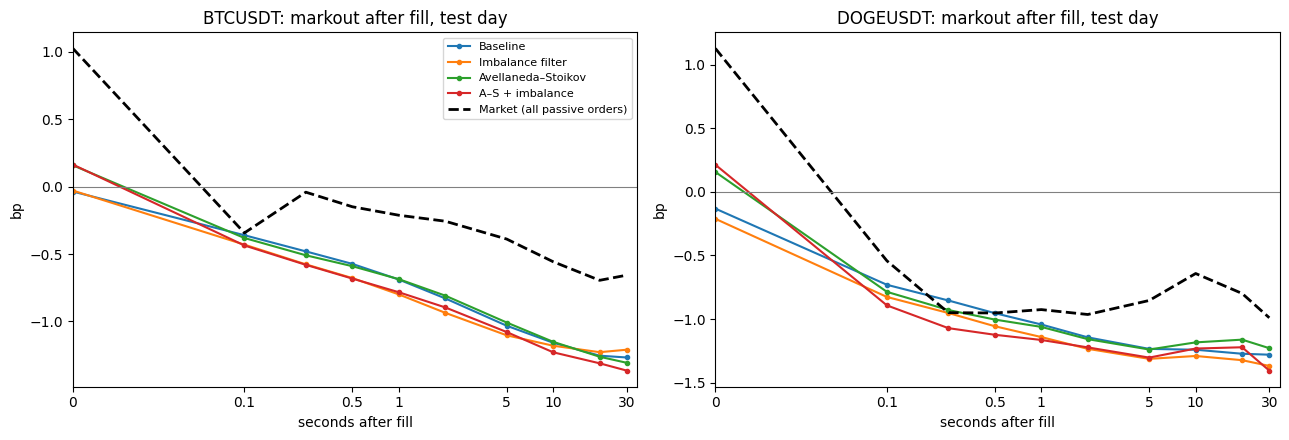

0s   0.1s  0.25s   0.5s     1s  \
BTCUSDT  Baseline                    -0.036 -0.360 -0.480 -0.573 -0.689   
         Imbalance filter            -0.029 -0.430 -0.576 -0.678 -0.799   
         Avellaneda–Stoikov           0.158 -0.381 -0.509 -0.590 -0.686   
         A–S + imbalance              0.164 -0.436 -0.580 -0.682 -0.783   
         Market (all passive orders)  1.025 -0.343 -0.041 -0.149 -0.212   
DOGEUSDT Baseline                    -0.132 -0.731 -0.854 -0.954 -1.043   
         Imbalance filter            -0.213 -0.826 -0.953 -1.057 -1.142   
         Avellaneda–Stoikov           0.155 -0.786 -0.929 -1.004 -1.062   
         A–S + imbalance              0.212 -0.893 -1.072 -1.124 -1.164   
         Market (all passive orders)  1.127 -0.543 -0.950 -0.953 -0.926   

                                         2s     5s    10s    20s    30s  
BTCUSDT  Baseline                    -0.829 -1.031 -1.157 -1.254 -1.267  
         Imbalance filter            -0.936 -1.102 -1.180 -1.228 -1.209  
         Avellaneda–Stoikov          -0.808 -1.008 -1.151 -1.261 -1.306  
         A–S + imbalance             -0.896 -1.078 -1.228 -1.310 -1.364  
         Market (all passive orders) -0.256 -0.389 -0.557 -0.695 -0.656  
DOGEUSDT Baseline                    -1.144 -1.235 -1.241 -1.273 -1.280  
         Imbalance filter            -1.234 -1.313 -1.290 -1.323 -1.369  
         Avellaneda–Stoikov          -1.158 -1.240 -1.184 -1.162 -1.229  
         A–S + imbalance             -1.223 -1.303 -1.232 -1.222 -1.405  
         Market (all passive orders) -0.964 -0.854 -0.642 -0.799 -0.990

In [ ]:
def markout_curve(times, side, price, qty, bk):
    out = []
    for h in HORIZONS_S:
        m = mid_at(bk, times + int(h * 1000))
        ok = ~np.isnan(m)
        out.append(1e4 * np.sum(side[ok] * (m[ok] - price[ok]) * qty[ok]) / np.sum(qty[ok] * price[ok]))
    return np.array(out)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
curves = {}
for ax, sym in zip(axes, INSTRUMENTS):
    bk = books[sym]
    for lab, r in runs[sym].items():
        f = r["fills"][r["fills"].day.isin(TEST_DAYS)]
        c = markout_curve(f.time.to_numpy(), f.side.to_numpy(), f.price.to_numpy(), f.qty.to_numpy(), bk)
        curves[(sym, nice(lab))] = c
        ax.plot(HORIZONS_S, c, marker="o", ms=3, label=nice(lab))
    tr = trades[sym]
    tr = tr[pd.to_datetime(tr.trade_ms, unit="ms").dt.strftime("%Y-%m-%d").isin(TEST_DAYS)]
    maker = np.where(tr.buyer_is_maker.to_numpy(bool), 1, -1)
    c = markout_curve(tr.trade_ms.to_numpy(), maker, tr.price.to_numpy(), tr.qty.to_numpy(), bk)
    curves[(sym, "Market (all passive orders)")] = c
    ax.plot(HORIZONS_S, c, "k--", lw=2, label="Market (all passive orders)")
    ax.axhline(0, c="grey", lw=0.8)
    ax.set_xscale("symlog", linthresh=0.1); ax.set_xlim(0, 35)
    ticks = [0, 0.1, 0.5, 1, 5, 10, 30]
    ax.set_xticks(ticks); ax.set_xticklabels([f"{h:g}" for h in ticks])
    ax.set_title(f"{sym}: markout after fill, test day"); ax.set_xlabel("seconds after fill"); ax.set_ylabel("bp")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/markout_curves.png", dpi=150); plt.show()
pd.DataFrame(curves, index=[f"{h:g}s" for h in HORIZONS_S]).T.round(3)

## 3. Break-even maker rebate

Net PnL = gross PnL − fee × value traded, so a strategy breaks even when the maker rebate equals −gross bps.
Standard Binance spot fees are a cost of about 10 bp; a rebate means the exchange pays you.

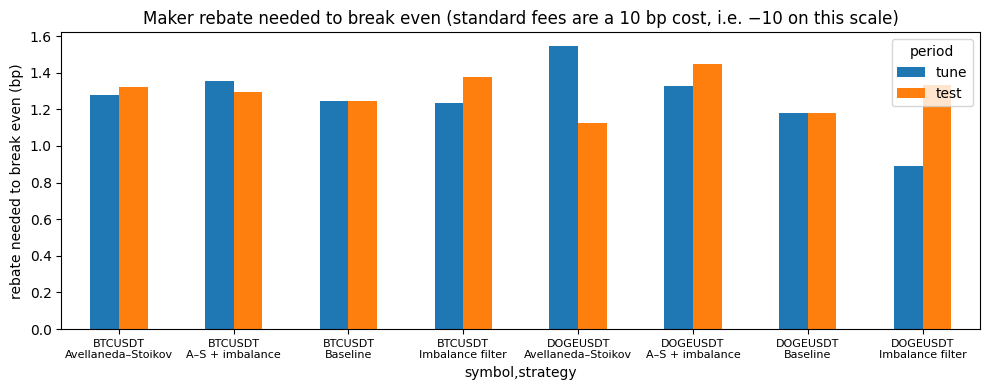

period                        tune   test
symbol   strategy                        
BTCUSDT  Avellaneda–Stoikov  1.280  1.324
         A–S + imbalance     1.352  1.296
         Baseline            1.245  1.243
         Imbalance filter    1.235  1.374
DOGEUSDT Avellaneda–Stoikov  1.543  1.126
         A–S + imbalance     1.330  1.447
         Baseline            1.179  1.179
         Imbalance filter    0.889  1.332

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
piv = decomp.pivot_table(index=["symbol", "strategy"], columns="period", values="breakeven_rebate_bps")
piv = piv[[c for c in ("tune", "test") if c in piv.columns]]
piv.plot.bar(ax=ax, color=["tab:blue", "tab:orange"][:len(piv.columns)])
ax.set_ylabel("rebate needed to break even (bp)")
ax.set_title("Maker rebate needed to break even (standard fees are a 10 bp cost, i.e. −10 on this scale)")
ax.set_xticklabels([f"{s}\n{st}" for s, st in piv.index], rotation=0, fontsize=8)
plt.tight_layout(); plt.savefig("figures/breakeven_rebate.png", dpi=150); plt.show()
piv.round(3)

## 4. Equity curves on the test day

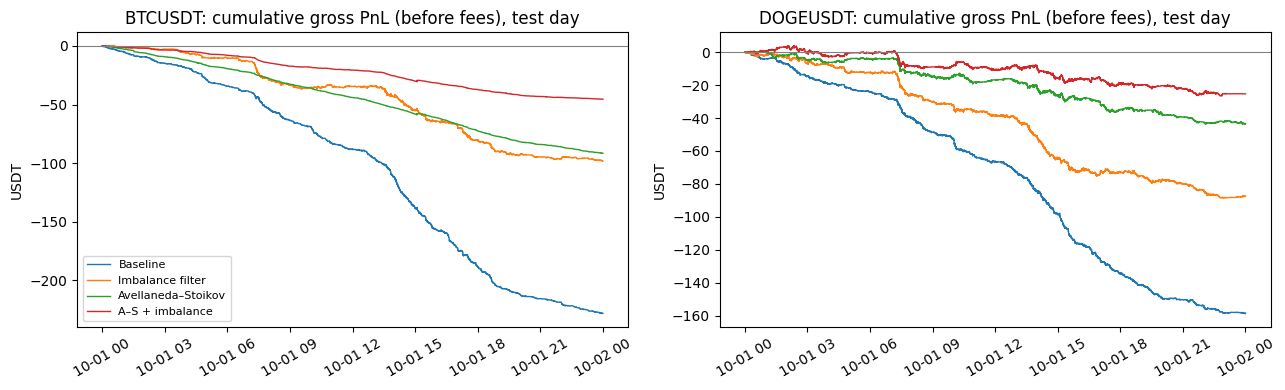

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, sym in zip(axes, INSTRUMENTS):
    for lab, r in runs[sym].items():
        e = r["equity"][r["equity"].day.isin(TEST_DAYS)]
        ax.plot(pd.to_datetime(e.time, unit="ms"), e.gross_pnl, label=nice(lab), lw=1)
    ax.axhline(0, c="grey", lw=0.8)
    ax.set_title(f"{sym}: cumulative gross PnL (before fees), test day"); ax.set_ylabel("USDT")
    ax.tick_params(axis="x", rotation=30)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/equity_curves.png", dpi=150); plt.show()

## 5. Final table for the README

In [ ]:
cols = ["symbol", "strategy", "period", "fills", "gross_bps", "spread_bps", "adverse_bps", "inventory_bps", "breakeven_rebate_bps"]
final = decomp[cols].sort_values(["symbol", "period", "strategy"], ascending=[True, False, True])
final.to_csv(f"{RESULTS}/final_table.csv", index=False)
final.round(2)

,symbol,strategy,period,fills,gross_bps,spread_bps,adverse_bps,inventory_bps,breakeven_rebate_bps
4,BTCUSDT,Avellaneda–Stoikov,tune,17311,-1.28,0.12,-1.24,-0.17,1.28
6,BTCUSDT,A–S + imbalance,tune,8270,-1.35,0.15,-1.35,-0.15,1.35
0,BTCUSDT,Baseline,tune,54749,-1.25,-0.03,-1.04,-0.18,1.25
2,BTCUSDT,Imbalance filter,tune,19509,-1.24,-0.02,-1.08,-0.13,1.24
5,BTCUSDT,Avellaneda–Stoikov,test,11035,-1.32,0.16,-1.31,-0.17,1.32
7,BTCUSDT,A–S + imbalance,test,5147,-1.30,0.17,-1.39,-0.07,1.30
1,BTCUSDT,Baseline,test,45575,-1.24,-0.04,-1.12,-0.09,1.24
3,BTCUSDT,Imbalance filter,test,13224,-1.37,-0.03,-1.15,-0.19,1.37
12,DOGEUSDT,Avellaneda–Stoikov,tune,11667,-1.54,0.44,-1.85,-0.13,1.54
14,DOGEUSDT,A–S + imbalance,tune,4694,-1.33,0.52,-2.08,0.23,1.33
